In [1]:
#Import and load
import pandas as pd
import sys
from pathlib import Path
sys.path.append(str(Path("/home/ibm-user/heart-risk-ibmz").resolve()))
from Preprocessing import preprocess

df = pd.read_csv("../../data/heart_disease_health_indicators_BRFSS2015.csv")
df.shape

(253680, 22)

In [2]:
df.columns

Index(['HeartDiseaseorAttack', 'HighBP', 'HighChol', 'CholCheck', 'BMI',
       'Smoker', 'Stroke', 'Diabetes', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='str')

In [3]:
df["HeartDiseaseorAttack"].value_counts(normalize=True)

HeartDiseaseorAttack
0.0    0.905814
1.0    0.094186
Name: proportion, dtype: float64

# Logistic Regression

In [4]:
#Logistic Regression libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

In [5]:
# #Split into training and testing data
# target = "HeartDiseaseorAttack"
# X = df.drop(columns=[target])
# y = df[target]

# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, stratify=y, random_state=42
# )
# X_train.shape, X_test.shape

In [36]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df):,}")

target = "HeartDiseaseorAttack"

# Features selected by the team's combined importance analysis (preprocessing notebook)
selected_features = ["Age", "GenHlth", "HighBP", "HighChol", "Sex",
                     "Stroke", "DiffWalk", "PhysHlth", "Diabetes", "Smoker"]
X = df[selected_features]
y = df[target]

# Same split as the team: 50% train / 30% validation / 20% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, train_size=0.50, stratify=y, random_state=25
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.40, stratify=y_temp, random_state=25
)

for name, part in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{name}: {len(part) / len(y):.0%} | positives: {part.mean():.2%}")

Rows after removing duplicates: 229,781
Train: 50% | positives: 10.32%
Val: 30% | positives: 10.32%
Test: 20% | positives: 10.32%


In [37]:
#Def evaluar
def evaluate(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "model": name,
        "threshold": threshold,
        "recall": recall_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "confusion": confusion_matrix(y_true, y_pred),
    }

In [38]:
#Train and Test
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)
log_reg.fit(X_train, y_train)
prob_log_reg = log_reg.predict_proba(X_test)[:, 1]

results = [evaluate("Logistic regression", y_test, prob_log_reg)]
pd.DataFrame(results).drop(columns="confusion")

,model,threshold,recall,precision,f1,roc_auc,pr_auc
0,Logistic regression,0.5,0.775506,0.25492,0.383709,0.834076,0.367105


# XGBoost

In [39]:
#Positive class weight
negatives = (y_train == 0).sum()
positives = (y_train == 1).sum()
pos_weight = negatives / positives
pos_weight

np.float64(8.688817675830663)

In [40]:
#Train XGBoost
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=pos_weight,
    eval_metric="aucpr",
    random_state=42
)
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [41]:
#Evaluation anc comparison
prob_xgb = xgb_model.predict_proba(X_test)[:, 1]
results.append(evaluate("XGBoost", y_test, prob_xgb))
pd.DataFrame(results).drop(columns="confusion")

,model,threshold,recall,precision,f1,roc_auc,pr_auc
0,Logistic regression,0.5,0.775506,0.254920,0.383709,0.834076,0.367105
1,XGBoost,0.5,0.797428,0.248033,0.378376,0.835386,0.369175


In [42]:
xgb_model.save_model("../../resultados/modelos/xgb.json")

# ANN

In [43]:
import time
import joblib
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(28)

# Neural networks need scaled inputs
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype("float32")
X_test_s = scaler.transform(X_test).astype("float32")

train_ds = TensorDataset(
    torch.from_numpy(X_train_s),
    torch.from_numpy(y_train.values.astype("float32"))
)
train_loader = DataLoader(train_ds, batch_size=1024, shuffle=True)

In [44]:
#Network definition
class HeartNet(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_features, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.layers(x).squeeze(1)

device = torch.device("cpu")
net = HeartNet(X_train_s.shape[1]).to(device)
net

HeartNet(
  (layers): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [45]:
#Train 
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(pos_weight)))
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

start = time.time()
for epoch in range(10):
    net.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(net(xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    print(f"Epoch {epoch + 1}: loss = {total_loss / len(train_ds):.4f}")

cpu_train_time = time.time() - start
print(f"Training time (CPU): {cpu_train_time:.1f} s")

Epoch 1: loss = 1.0058
Epoch 2: loss = 0.9130
Epoch 3: loss = 0.9078
Epoch 4: loss = 0.9035
Epoch 5: loss = 0.9039
Epoch 6: loss = 0.9015
Epoch 7: loss = 0.9019
Epoch 8: loss = 0.9002
Epoch 9: loss = 0.8975
Epoch 10: loss = 0.9006
Training time (CPU): 8.5 s


In [46]:
#Evaluation and Comparison
net.eval()
start = time.time()
with torch.no_grad():
    logits = net(torch.from_numpy(X_test_s).to(device))
    prob_nn = torch.sigmoid(logits).cpu().numpy()
cpu_infer_time = time.time() - start
print(f"Inference time (CPU): {cpu_infer_time:.3f} s")

results.append(evaluate("Neural network (CPU)", y_test, prob_nn))
pd.DataFrame(results).drop(columns="confusion")

Inference time (CPU): 0.015 s


,model,threshold,recall,precision,f1,roc_auc,pr_auc
0,Logistic regression,0.5,0.775506,0.254920,0.383709,0.834076,0.367105
1,XGBoost,0.5,0.797428,0.248033,0.378376,0.835386,0.369175
2,Neural network (CPU),0.5,0.819140,0.242966,0.374771,0.836918,0.371917


In [47]:
torch.save(net.state_dict(), "../../resultados/modelos/heartnet_cpu.pt")
joblib.dump(scaler, "../../resultados/modelos/scaler.joblib")

['../../resultados/modelos/scaler.joblib']

In [48]:
#Verifying accelerator 
import numpy as np
import torch_nnpa

print("NNPA available:", torch.nnpa.is_available())
print("Telum II available:", torch.nnpa.is_telum2_available())
nnpa_device = torch_nnpa.device()
print("Device:", nnpa_device)

NNPA available: True
Telum II available: True
Device: nnpa:0


In [49]:
# Copy the trained CPU weights into a model on the NNPA device
net_nnpa = HeartNet(X_train_s.shape[1])
net_nnpa.load_state_dict(net.state_dict())
net_nnpa = net_nnpa.to(nnpa_device)
net_nnpa.eval()

def predict_in_batches(model, X, device, batch_size=4096):
    probs = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = torch.from_numpy(X[i:i + batch_size]).to(device)
            probs.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(probs)

# Warm-up run: the first call includes one-time setup costs
_ = predict_in_batches(net_nnpa, X_test_s[:4096], nnpa_device)

start = time.time()
prob_nn_nnpa = predict_in_batches(net_nnpa, X_test_s, nnpa_device)
nnpa_infer_time = time.time() - start
print(f"Inference time (NNPA): {nnpa_infer_time:.3f} s")

Inference time (NNPA): 0.005 s


In [50]:
max_diff = np.abs(prob_nn - prob_nn_nnpa).max()
print(f"Max probability difference CPU vs NNPA: {max_diff:.5f}")
print(f"Inference time  CPU: {cpu_infer_time:.3f} s | NNPA: {nnpa_infer_time:.3f} s")

results.append(evaluate("Neural network (NNPA)", y_test, prob_nn_nnpa))
pd.DataFrame(results).drop(columns="confusion")

Max probability difference CPU vs NNPA: 0.00103
Inference time  CPU: 0.015 s | NNPA: 0.005 s


,model,threshold,recall,precision,f1,roc_auc,pr_auc
0,Logistic regression,0.5,0.775506,0.254920,0.383709,0.834076,0.367105
1,XGBoost,0.5,0.797428,0.248033,0.378376,0.835386,0.369175
2,Neural network (CPU),0.5,0.819140,0.242966,0.374771,0.836918,0.371917
3,Neural network (NNPA),0.5,0.818929,0.242888,0.374656,0.836914,0.371792


In [51]:
def benchmark(model, X, device, runs=20):
    predict_in_batches(model, X[:4096], device)  # warm-up
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        predict_in_batches(model, X, device)
        times.append(time.perf_counter() - start)
    return np.median(times)

cpu_time = benchmark(net, X_test_s, device)
nnpa_time = benchmark(net_nnpa, X_test_s, nnpa_device)

n = len(X_test_s)
print(f"CPU : {cpu_time * 1000:.2f} ms  ({n / cpu_time:,.0f} predictions/s)")
print(f"NNPA: {nnpa_time * 1000:.2f} ms  ({n / nnpa_time:,.0f} predictions/s)")
print(f"Speedup: {cpu_time / nnpa_time:.1f}x")

CPU : 14.31 ms  (3,212,223 predictions/s)
NNPA: 3.73 ms  (12,311,862 predictions/s)
Speedup: 3.8x


In [52]:
pd.DataFrame(results).drop(columns="confusion").to_csv(
    "../../resultados/model_comparison.csv", index=False
)

# Interpretability

In [53]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200,
    "font.size": 13, "axes.titlesize": 16, "axes.labelsize": 14
})
FIG_DIR = "../../resultados/figuras/"

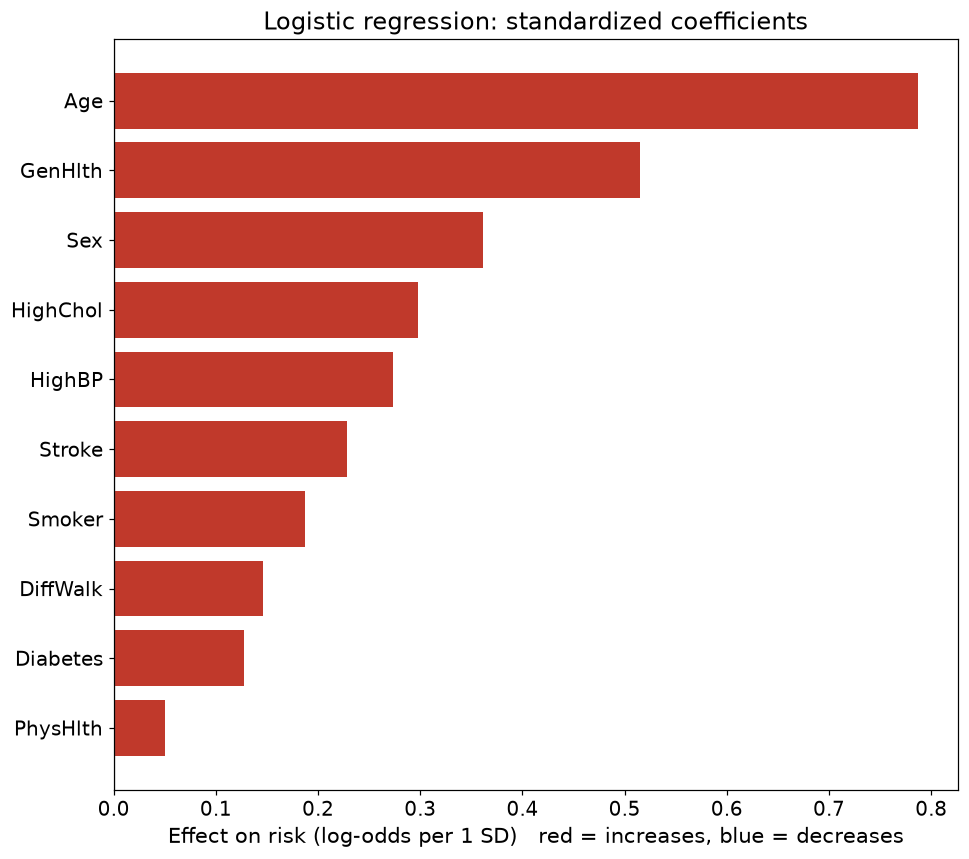

In [54]:
coefs = pd.Series(
    log_reg.named_steps["logisticregression"].coef_[0], index=X.columns
).sort_values()

colors = ["#C0392B" if c > 0 else "#2E86C1" for c in coefs]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(coefs.index, coefs.values, color=colors)
ax.axvline(0, color="gray", lw=0.8)
ax.set_title("Logistic regression: standardized coefficients")
ax.set_xlabel("Effect on risk (log-odds per 1 SD)   red = increases, blue = decreases")
plt.tight_layout()
plt.savefig(FIG_DIR + "01_logreg_coefficients.png")
plt.show()

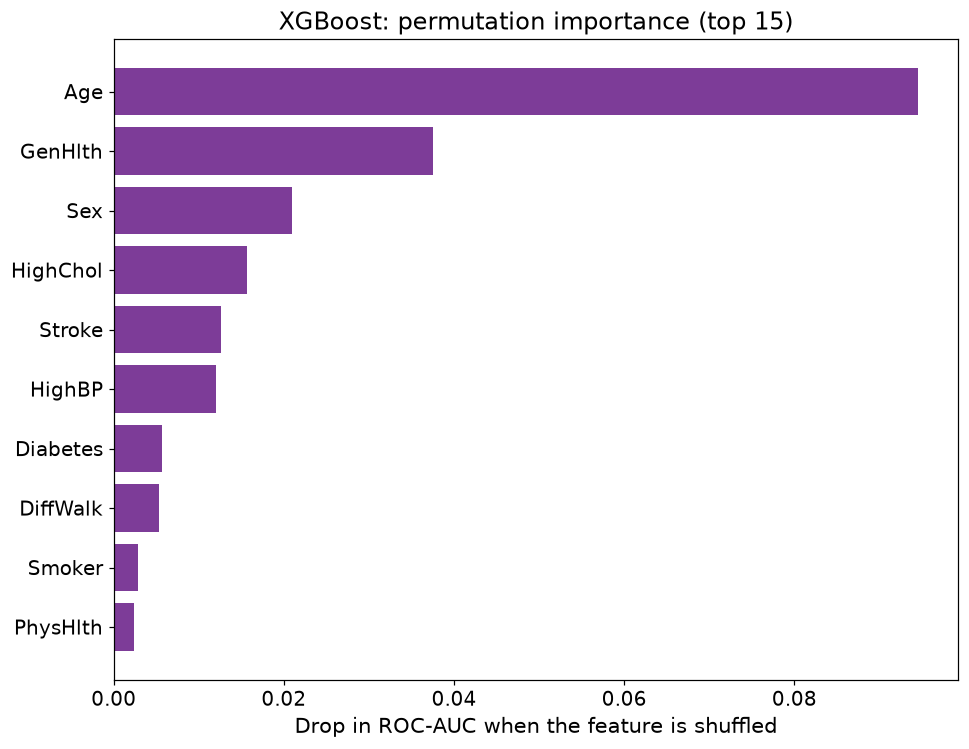

In [55]:
from sklearn.inspection import permutation_importance

sample = X_test.sample(10000, random_state=42)
perm = permutation_importance(
    xgb_model, sample, y_test.loc[sample.index],
    scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1
)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(perm_imp.index, perm_imp.values, color="#7D3C98")
ax.set_title("XGBoost: permutation importance (top 15)")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.tight_layout()
plt.savefig(FIG_DIR + "02_xgb_permutation_importance.png")
plt.show()

In [56]:
joblib.dump(log_reg, "../../resultados/modelos/log_reg.joblib")

['../../resultados/modelos/log_reg.joblib']

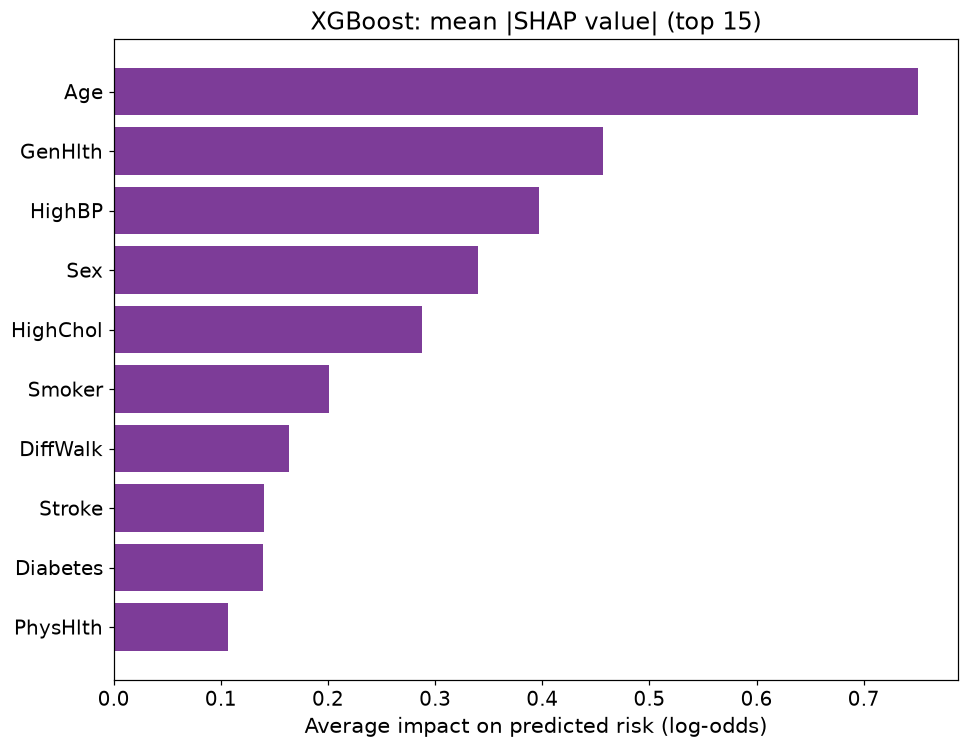

In [57]:
import xgboost as xgb

# pred_contribs=True returns SHAP values (TreeSHAP); the last column is the base value
contribs = xgb_model.get_booster().predict(xgb.DMatrix(sample), pred_contribs=True)
shap_df = pd.DataFrame(contribs[:, :-1], columns=X.columns, index=sample.index)
base_value = contribs[0, -1]

mean_abs = shap_df.abs().mean().sort_values().tail(15)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(mean_abs.index, mean_abs.values, color="#7D3C98")
ax.set_title("XGBoost: mean |SHAP value| (top 15)")
ax.set_xlabel("Average impact on predicted risk (log-odds)")
plt.tight_layout()
plt.savefig(FIG_DIR + "03_xgb_shap_global.png")
plt.show()

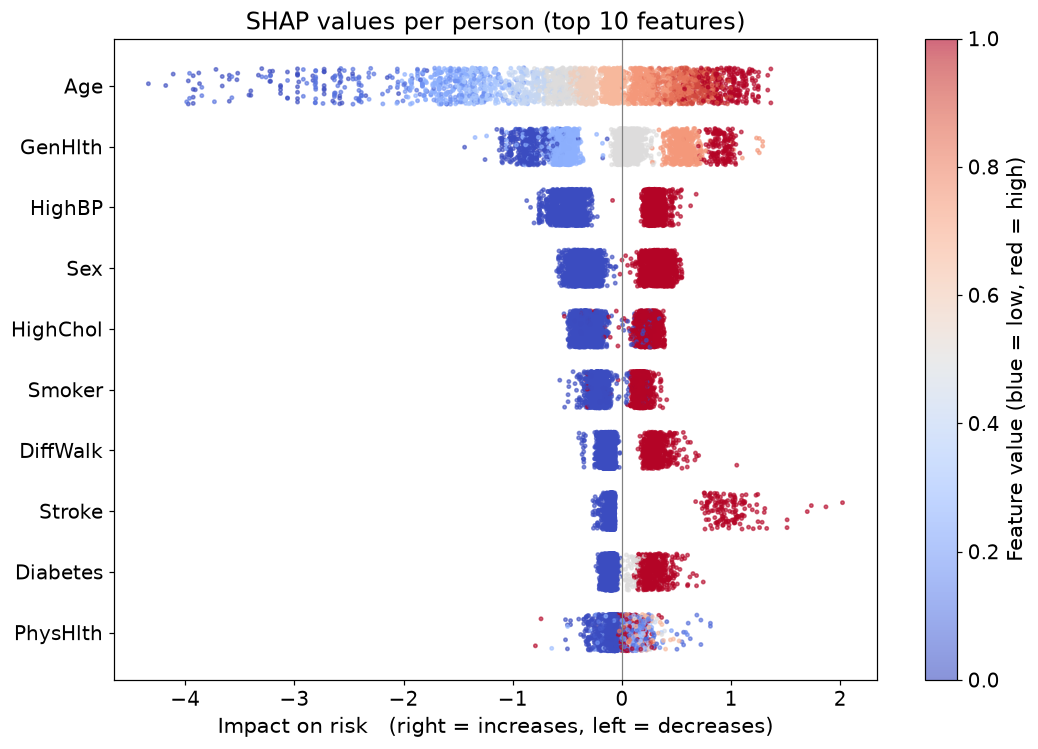

In [58]:
rng = np.random.default_rng(42)
plot_idx = rng.choice(len(shap_df), 3000, replace=False)
top_features = mean_abs.index[-10:]

fig, ax = plt.subplots(figsize=(10, 7))
for i, feat in enumerate(top_features):
    vals = shap_df[feat].values[plot_idx]
    fv = sample[feat].values[plot_idx]
    norm = (fv - fv.min()) / (fv.max() - fv.min() + 1e-9)
    y_pos = i + rng.uniform(-0.3, 0.3, len(vals))
    sc = ax.scatter(vals, y_pos, c=norm, cmap="coolwarm", s=5, alpha=0.6)

ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features)
ax.axvline(0, color="gray", lw=0.8)
ax.set_title("SHAP values per person (top 10 features)")
ax.set_xlabel("Impact on risk   (right = increases, left = decreases)")
cbar = plt.colorbar(sc)
cbar.set_label("Feature value (blue = low, red = high)")
plt.tight_layout()
plt.savefig(FIG_DIR + "04_xgb_shap_beeswarm.png")
plt.show()

Patient 4057 | predicted risk: 76.7%


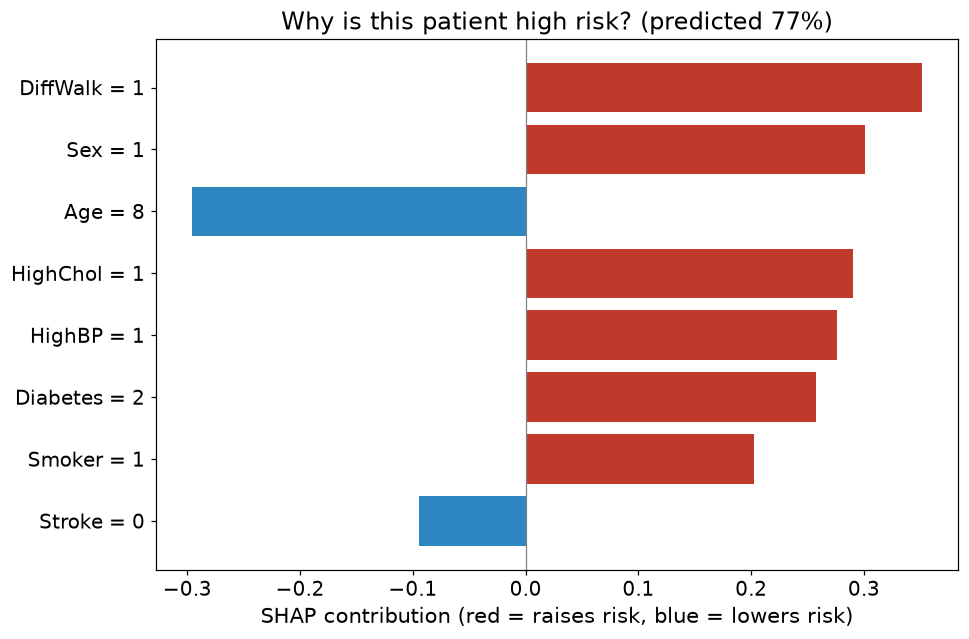

In [59]:
probs_sample = pd.Series(xgb_model.predict_proba(sample)[:, 1], index=sample.index)
candidates = probs_sample[(y_test.loc[sample.index] == 1) & probs_sample.between(0.6, 0.9)]
patient_id = candidates.index[0]
patient = X_test.loc[patient_id]
print(f"Patient {patient_id} | predicted risk: {probs_sample[patient_id]:.1%}")

contrib = shap_df.loc[patient_id]
top_contrib = contrib.reindex(contrib.abs().sort_values().index).tail(8)
labels = [f"{f} = {patient[f]:g}" for f in top_contrib.index]
colors = ["#C0392B" if v > 0 else "#2E86C1" for v in top_contrib]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(labels, top_contrib.values, color=colors)
ax.axvline(0, color="gray", lw=0.8)
ax.set_title(f"Why is this patient high risk? (predicted {probs_sample[patient_id]:.0%})")
ax.set_xlabel("SHAP contribution (red = raises risk, blue = lowers risk)")
plt.tight_layout()
plt.savefig(FIG_DIR + "05_patient_shap.png")
plt.show()

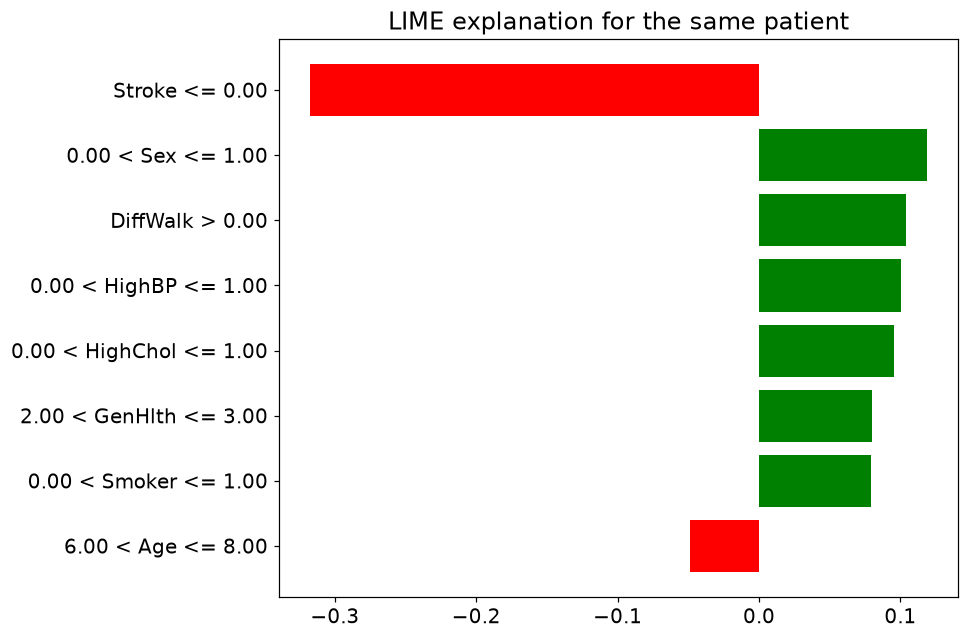

In [60]:
from lime.lime_tabular import LimeTabularExplainer

explainer = LimeTabularExplainer(
    X_train.values,
    feature_names=list(X.columns),
    class_names=["No disease", "Heart disease"],
    discretize_continuous=True,
    random_state=42
)

def xgb_predict(arr):
    return xgb_model.predict_proba(pd.DataFrame(arr, columns=X.columns))

lime_exp = explainer.explain_instance(patient.values, xgb_predict, num_features=8)
fig = lime_exp.as_pyplot_figure()
fig.set_size_inches(9, 6)
plt.title("LIME explanation for the same patient")
plt.tight_layout()
plt.savefig(FIG_DIR + "06_patient_lime.png")
plt.show()

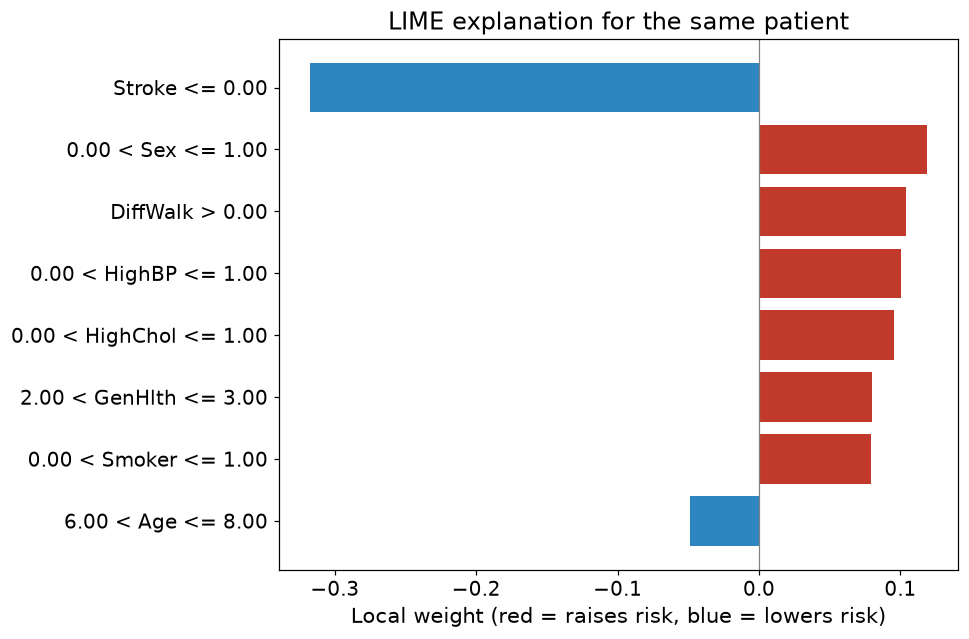

In [61]:
lime_list = lime_exp.as_list()[::-1]
lime_labels = [item[0] for item in lime_list]
lime_values = [item[1] for item in lime_list]
lime_colors = ["#C0392B" if v > 0 else "#2E86C1" for v in lime_values]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(lime_labels, lime_values, color=lime_colors)
ax.axvline(0, color="gray", lw=0.8)
ax.set_title("LIME explanation for the same patient")
ax.set_xlabel("Local weight (red = raises risk, blue = lowers risk)")
plt.tight_layout()
plt.savefig(FIG_DIR + "06_patient_lime.png")
plt.show()

In [62]:
from itertools import combinations

# Each action: when it applies to a patient, and how it changes their values
ACTIONS = {
    "Smoker":       {"label": "Quit smoking",
                     "applies": lambda p: p["Smoker"] == 1,
                     "apply":   lambda p: p.update(Smoker=0)},
    "PhysActivity": {"label": "Be physically active",
                     "applies": lambda p: p["PhysActivity"] == 0,
                     "apply":   lambda p: p.update(PhysActivity=1)},
    "Fruits":       {"label": "Eat fruit daily",
                     "applies": lambda p: p["Fruits"] == 0,
                     "apply":   lambda p: p.update(Fruits=1)},
    "Veggies":      {"label": "Eat vegetables daily",
                     "applies": lambda p: p["Veggies"] == 0,
                     "apply":   lambda p: p.update(Veggies=1)},
    "BMI":          {"label": "Reduce BMI by 10%",
                     "applies": lambda p: p["BMI"] > 25,
                     "apply":   lambda p: p.update(BMI=max(25, round(p["BMI"] * 0.9)))},
    "HighBP":       {"label": "Control blood pressure",
                     "applies": lambda p: p["HighBP"] == 1,
                     "apply":   lambda p: p.update(HighBP=0)},
    "HighChol":     {"label": "Control cholesterol",
                     "applies": lambda p: p["HighChol"] == 1,
                     "apply":   lambda p: p.update(HighChol=0)},
    "Diabetes":     {"label": "Control diabetes",
                     "applies": lambda p: p["Diabetes"] > 0,
                     "apply":   lambda p: p.update(Diabetes=0)},
}

In [63]:
def nn_risk(rows):
    arr = scaler.transform(pd.DataFrame(rows, columns=X.columns)).astype("float32")
    return predict_in_batches(net_nnpa, arr, nnpa_device)

def counterfactuals(patient_row):
    base = patient_row.to_dict()
    available = [k for k, a in ACTIONS.items() if k in base and a["applies"](base)]
    scenarios, combos = [], []
    for r in range(len(available) + 1):
        for combo in combinations(available, r):
            scenario = dict(base)
            for k in combo:
                ACTIONS[k]["apply"](scenario)
            scenarios.append(scenario)
            combos.append(combo)
    start = time.perf_counter()
    risks = nn_risk(scenarios)
    elapsed = time.perf_counter() - start
    out = pd.DataFrame({"changes": combos,
                        "n_changes": [len(c) for c in combos],
                        "risk": risks})
    return out, elapsed

cf, elapsed = counterfactuals(X_test.loc[patient_id])
base_risk = cf.loc[cf.n_changes == 0, "risk"].iloc[0]
print(f"Baseline risk (neural network): {base_risk:.1%}")
print(f"{len(cf)} scenarios evaluated on NNPA in {elapsed * 1000:.1f} ms")

Baseline risk (neural network): 75.5%
16 scenarios evaluated on NNPA in 1.9 ms


In [64]:
print(X.shape, X_test.shape)
print(X.columns.tolist())

(229781, 10) (45957, 10)
['Age', 'GenHlth', 'HighBP', 'HighChol', 'Sex', 'Stroke', 'DiffWalk', 'PhysHlth', 'Diabetes', 'Smoker']


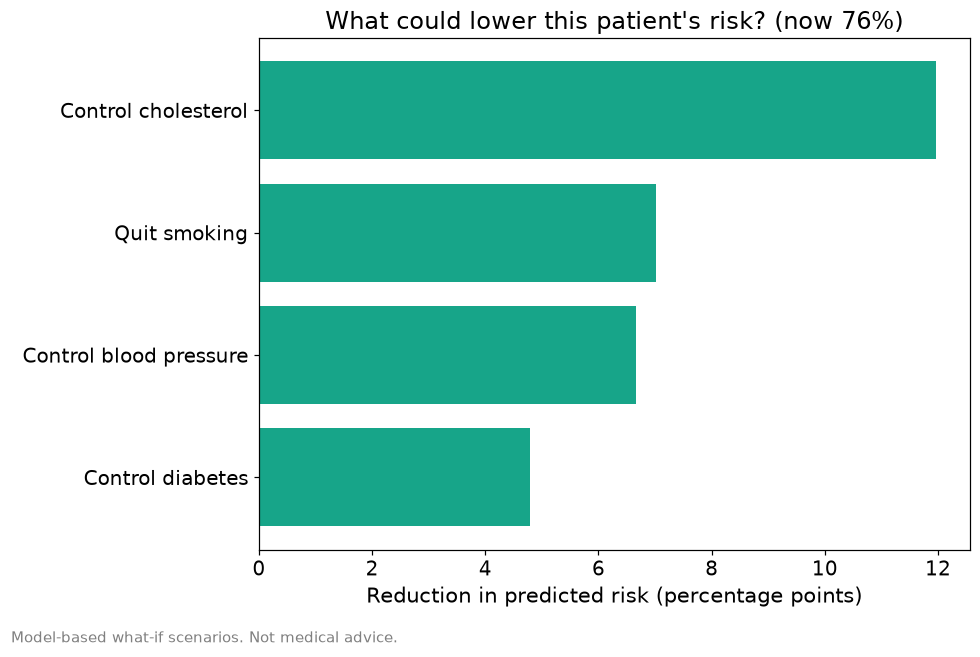

,action,risk,reduction_pp
4,Control diabetes,0.707405,4.787147
2,Control blood pressure,0.688678,6.659836
1,Quit smoking,0.685107,7.016885
3,Control cholesterol,0.635675,11.960131


In [65]:
single = cf[cf.n_changes == 1].copy()
single["action"] = single.changes.apply(lambda c: ACTIONS[c[0]]["label"])
single["reduction_pp"] = (base_risk - single.risk) * 100
single = single.sort_values("reduction_pp")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(single.action, single.reduction_pp, color="#17A589")
ax.set_title(f"What could lower this patient's risk? (now {base_risk:.0%})")
ax.set_xlabel("Reduction in predicted risk (percentage points)")
fig.text(0.01, 0.01, "Model-based what-if scenarios. Not medical advice.",
         fontsize=10, color="gray")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG_DIR + "07_patient_counterfactual_actions.png")
plt.show()
single[["action", "risk", "reduction_pp"]]

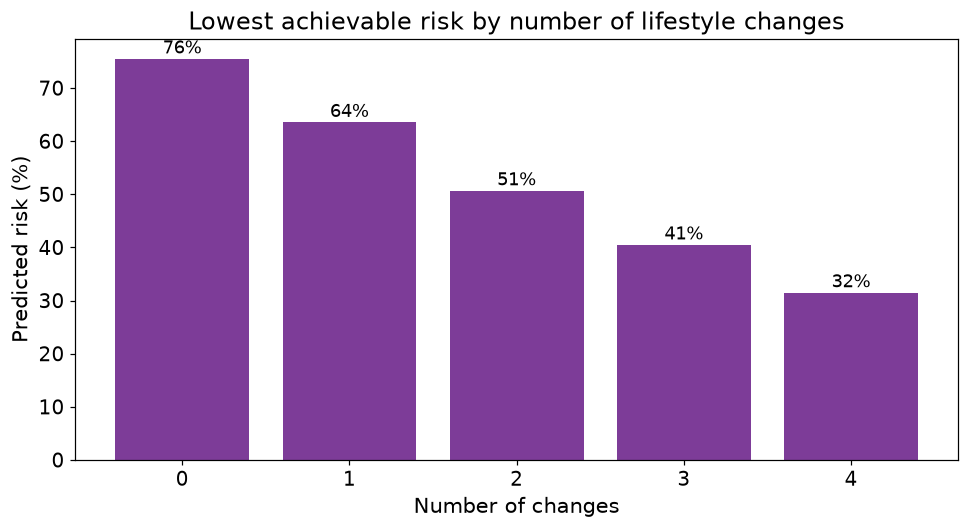

,n_changes,plan,risk
0,0,No changes,0.755276
3,1,Control cholesterol,0.635675
10,2,Control cholesterol + Control diabetes,0.507034
13,3,Quit smoking + Control cholesterol + Control diabetes,0.405096
15,4,Quit smoking + Control blood pressure + Control cholesterol + Control diabetes,0.315103


In [66]:
best = cf.loc[cf.groupby("n_changes")["risk"].idxmin()].copy()
best["plan"] = best.changes.apply(
    lambda c: " + ".join(ACTIONS[k]["label"] for k in c) or "No changes"
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(best.n_changes, best.risk * 100, color="#7D3C98")
for x_pos, r in zip(best.n_changes, best.risk):
    ax.text(x_pos, r * 100 + 1, f"{r:.0%}", ha="center", fontsize=12)
ax.set_title("Lowest achievable risk by number of lifestyle changes")
ax.set_xlabel("Number of changes")
ax.set_ylabel("Predicted risk (%)")
ax.set_xticks(best.n_changes)
plt.tight_layout()
plt.savefig(FIG_DIR + "08_patient_best_plan.png")
plt.show()

pd.set_option("display.max_colwidth", None)
best[["n_changes", "plan", "risk"]]

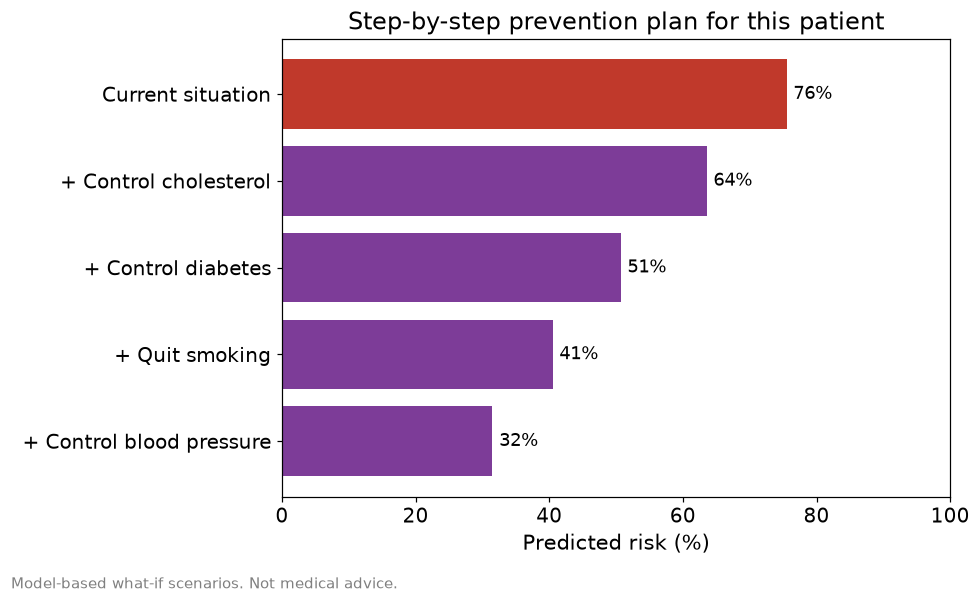

,step,risk
0,Current situation,0.755276
1,+ Control cholesterol,0.635675
2,+ Control diabetes,0.507034
3,+ Quit smoking,0.405096
4,+ Control blood pressure,0.315103


In [67]:
MIN_EFFECT_PP = 1.0

# Only recommend actions with a meaningful individual effect
useful = set(single.loc[single.reduction_pp >= MIN_EFFECT_PP, "changes"].apply(lambda c: c[0]))
risk_of = {frozenset(c): r for c, r in zip(cf.changes, cf.risk)}

# Greedy path: at each step add the action that lowers risk the most
path, chosen, remaining = [("Current situation", base_risk)], frozenset(), set(useful)
while remaining:
    next_action = min(remaining, key=lambda k: risk_of[chosen | {k}])
    chosen = chosen | {next_action}
    remaining.remove(next_action)
    path.append((f"+ {ACTIONS[next_action]['label']}", risk_of[chosen]))

path_df = pd.DataFrame(path, columns=["step", "risk"])
single = single[single.reduction_pp >= MIN_EFFECT_PP]
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(path_df.step[::-1], path_df.risk[::-1] * 100,
               color=["#7D3C98"] * (len(path_df) - 1) + ["#C0392B"])
for bar, r in zip(bars, path_df.risk[::-1]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"{r:.0%}", va="center", fontsize=12)
ax.set_xlim(0, 100)
ax.set_title("Step-by-step prevention plan for this patient")
ax.set_xlabel("Predicted risk (%)")
fig.text(0.01, 0.01, "Model-based what-if scenarios. Not medical advice.",
         fontsize=10, color="gray")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG_DIR + "08_patient_best_plan.png")
plt.show()
path_df

In [68]:
from sklearn.metrics import precision_recall_curve

X_val_s = scaler.transform(X_val).astype("float32")
prob_val = predict_in_batches(net_nnpa, X_val_s, nnpa_device)

prec, rec, thr = precision_recall_curve(y_val, prob_val)
prec, rec = prec[:-1], rec[:-1]  # align with thresholds

f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
t_f1 = thr[np.argmax(f1_scores)]        # best balance precision/recall
t_low = thr[rec >= 0.90].max()          # keeps 90% of cases above "Low"
t_high = thr[prec >= 0.40].min()        # "High" tier: at least 40% are true cases

print(f"F1-optimal threshold:        {t_f1:.3f}")
print(f"Low/Moderate cut (recall 90%): {t_low:.3f}")
print(f"Moderate/High cut (prec 40%):  {t_high:.3f}")

F1-optimal threshold:        0.705
Low/Moderate cut (recall 90%): 0.365
Moderate/High cut (prec 40%):  0.770


In [69]:
results.append(evaluate("Neural network (NNPA), F1 threshold", y_test, prob_nn_nnpa, threshold=t_f1))
results.append(evaluate("Neural network (NNPA), screening threshold", y_test, prob_nn_nnpa, threshold=t_low))
pd.DataFrame(results).drop(columns="confusion")

,model,threshold,recall,precision,f1,roc_auc,pr_auc
0,Logistic regression,0.500000,0.775506,0.254920,0.383709,0.834076,0.367105
1,XGBoost,0.500000,0.797428,0.248033,0.378376,0.835386,0.369175
2,Neural network (CPU),0.500000,0.819140,0.242966,0.374771,0.836918,0.371917
3,Neural network (NNPA),0.500000,0.818929,0.242888,0.374656,0.836914,0.371792
4,"Neural network (NNPA), F1 threshold",0.704973,0.558179,0.338186,0.421187,0.836914,0.371792
5,"Neural network (NNPA), screening threshold",0.364778,0.900295,0.204139,0.332814,0.836914,0.371792


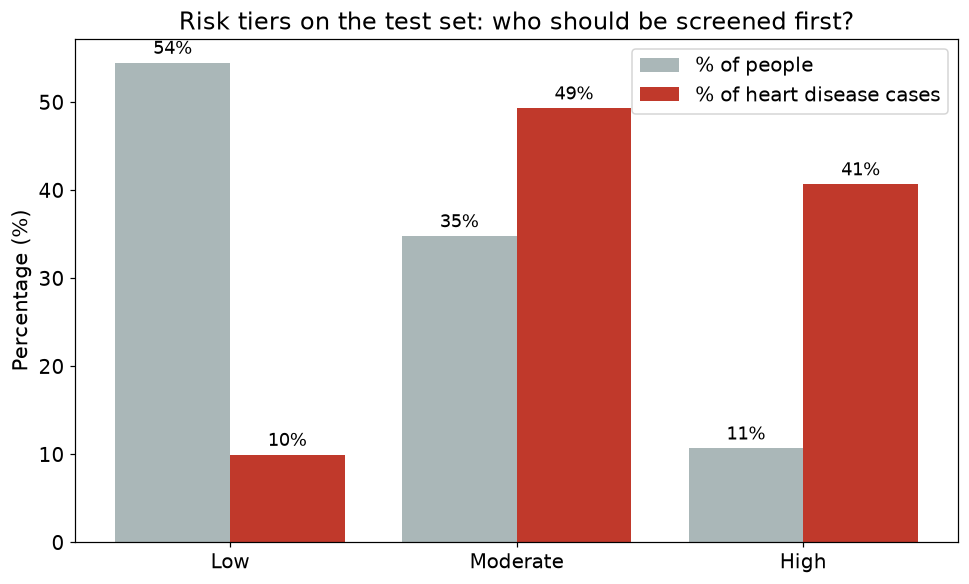

,people,cases,share_of_people,share_of_cases,observed_rate
tier,,,,,
Low,25046,473.0,0.544988,0.099705,0.018885
Moderate,15996,2340.0,0.348064,0.493255,0.146287
High,4915,1931.0,0.106948,0.407040,0.392879


In [70]:
tiers = pd.cut(prob_nn_nnpa, bins=[0, t_low, t_high, 1],
               labels=["Low", "Moderate", "High"], include_lowest=True)
tier_df = pd.DataFrame({"tier": tiers, "y": y_test.values})

summary = tier_df.groupby("tier", observed=False).agg(people=("y", "size"), cases=("y", "sum"))
summary["share_of_people"] = summary.people / summary.people.sum()
summary["share_of_cases"] = summary.cases / summary.cases.sum()
summary["observed_rate"] = summary.cases / summary.people

x_pos = np.arange(len(summary))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(x_pos - 0.2, summary.share_of_people * 100, width=0.4, label="% of people", color="#AAB7B8")
ax.bar(x_pos + 0.2, summary.share_of_cases * 100, width=0.4, label="% of heart disease cases", color="#C0392B")
for i, (p, c) in enumerate(zip(summary.share_of_people, summary.share_of_cases)):
    ax.text(i - 0.2, p * 100 + 1, f"{p:.0%}", ha="center", fontsize=12)
    ax.text(i + 0.2, c * 100 + 1, f"{c:.0%}", ha="center", fontsize=12)
ax.set_xticks(x_pos)
ax.set_xticklabels(summary.index)
ax.set_ylabel("Percentage (%)")
ax.set_title("Risk tiers on the test set: who should be screened first?")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + "09_risk_tiers.png")
plt.show()
summary

In [71]:
from scipy.special import logit

def to_logit(p):
    return logit(np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)).reshape(-1, 1)

platt = LogisticRegression()
platt.fit(to_logit(prob_val), y_val)

def calibrate(p):
    return platt.predict_proba(to_logit(p))[:, 1]

cal_test = calibrate(prob_nn_nnpa)
check = pd.DataFrame({"tier": tiers, "raw_score": prob_nn_nnpa,
                      "calibrated": cal_test, "observed": y_test.values})
print(check.groupby("tier", observed=False)[["raw_score", "calibrated", "observed"]].mean())
print(f"\nOverall | calibrated mean: {cal_test.mean():.3f} | observed rate: {y_test.mean():.3f}")

joblib.dump(platt, "../../resultados/modelos/calibrator.joblib")

          raw_score  calibrated  observed
tier                                     
Low        0.143477    0.019109  0.018885
Moderate   0.576631    0.144166  0.146287
High       0.841337    0.394735  0.392879

Overall | calibrated mean: 0.103 | observed rate: 0.103


['../../resultados/modelos/calibrator.joblib']

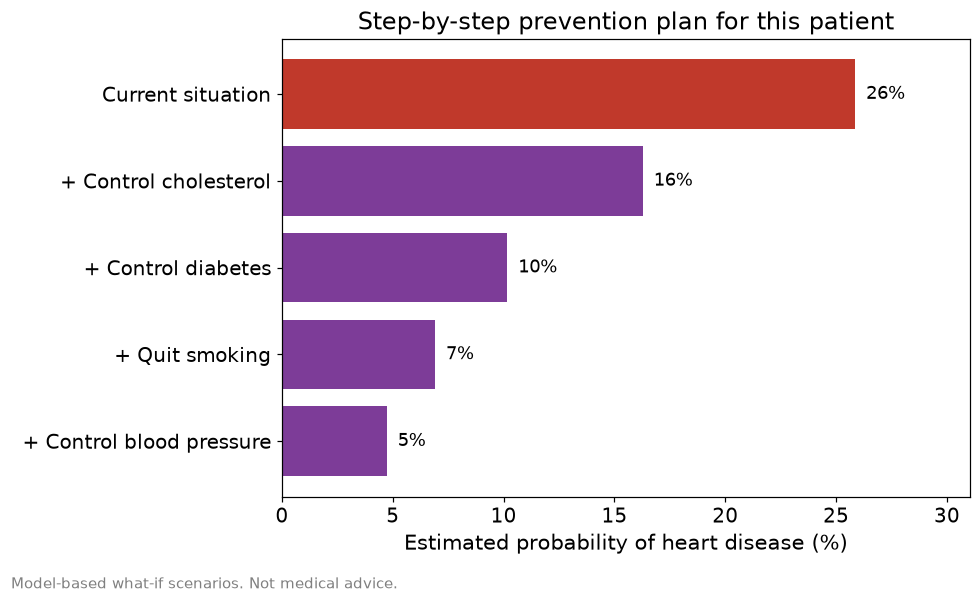

,step,risk,calibrated_risk
0,Current situation,0.755276,0.258539
1,+ Control cholesterol,0.635675,0.162748
2,+ Control diabetes,0.507034,0.101613
3,+ Quit smoking,0.405096,0.069010
4,+ Control blood pressure,0.315103,0.047258


In [72]:
path_df["calibrated_risk"] = calibrate(path_df.risk.values)

fig, ax = plt.subplots(figsize=(9, 5.5))
vals = path_df.calibrated_risk[::-1]
bars = ax.barh(path_df.step[::-1], vals * 100,
               color=["#7D3C98"] * (len(path_df) - 1) + ["#C0392B"])
for bar, r in zip(bars, vals):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{r:.0%}", va="center", fontsize=12)
ax.set_xlim(0, max(vals) * 100 * 1.2)
ax.set_title("Step-by-step prevention plan for this patient")
ax.set_xlabel("Estimated probability of heart disease (%)")
fig.text(0.01, 0.01, "Model-based what-if scenarios. Not medical advice.",
         fontsize=10, color="gray")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(FIG_DIR + "08_patient_best_plan.png")
plt.show()
path_df

In [73]:
import json

N_DEMO = 300
demo_ids = X_test.index[:N_DEMO]
X_demo = X_test.loc[demo_ids]

# Model explanation: SHAP values from XGBoost
demo_contribs = xgb_model.get_booster().predict(xgb.DMatrix(X_demo), pred_contribs=True)[:, :-1]
demo_shap = pd.DataFrame(demo_contribs, columns=X.columns, index=demo_ids)

# Risk: neural network on NNPA, calibrated
raw_demo = predict_in_batches(net_nnpa, scaler.transform(X_demo).astype("float32"), nnpa_device)
cal_demo = calibrate(raw_demo)
tier_demo = pd.cut(raw_demo, bins=[0, t_low, t_high, 1],
                   labels=["Low", "Moderate", "High"], include_lowest=True)

def top_drivers(pid, k=3):
    s = demo_shap.loc[pid]
    s = s[s > 0].sort_values(ascending=False).head(k)
    return [{"feature": f, "value": float(X_demo.loc[pid, f]), "impact": round(float(v), 3)}
            for f, v in s.items()]

def prevention_plan(pid):
    cf_p, _ = counterfactuals(X_demo.loc[pid])
    base = cf_p.loc[cf_p.n_changes == 0, "risk"].iloc[0]
    single_p = cf_p[cf_p.n_changes == 1]
    useful_p = {c[0] for c, r in zip(single_p.changes, single_p.risk)
                if (base - r) * 100 >= MIN_EFFECT_PP}
    risk_map = {frozenset(c): r for c, r in zip(cf_p.changes, cf_p.risk)}
    steps, chosen, remaining = [], frozenset(), set(useful_p)
    while remaining:
        nxt = min(remaining, key=lambda k: risk_map[chosen | {k}])
        chosen = chosen | {nxt}
        remaining.remove(nxt)
        steps.append({"action": ACTIONS[nxt]["label"],
                      "probability_after": round(float(calibrate([risk_map[chosen]])[0]), 3)})
    return steps

start = time.perf_counter()
records = []
for pid, raw, cal, tier in zip(demo_ids, raw_demo, cal_demo, tier_demo):
    records.append({
        "id": int(pid),
        "y_true": int(y_test.loc[pid]),
        "risk_score": round(float(raw), 3),
        "probability": round(float(cal), 3),
        "tier": str(tier),
        "features": {k: float(v) for k, v in X_demo.loc[pid].items()},
        "drivers": top_drivers(pid),
        "shap": {k: round(float(v), 4) for k, v in demo_shap.loc[pid].items()},
        "plan": prevention_plan(pid),
    })

with open("../../resultados/demo_patients.json", "w") as fh:
    json.dump(records, fh, indent=2)
print(f"Exported {len(records)} patients in {time.perf_counter() - start:.1f} s")

Exported 300 patients in 0.6 s


In [74]:
print("Thresholds (chosen on validation):")
print(f"  F1: {t_f1:.3f} | Low/Moderate: {t_low:.3f} | Moderate/High: {t_high:.3f}\n")

print("Model comparison (test set):")
print(pd.DataFrame(results).drop(columns="confusion").to_string(), "\n")

print("Risk tiers (test set):")
print(summary.to_string(), "\n")

print("Calibration check (test set):")
print(check.groupby("tier", observed=False)[["raw_score", "calibrated", "observed"]].mean())

Thresholds (chosen on validation):
  F1: 0.705 | Low/Moderate: 0.365 | Moderate/High: 0.770

Model comparison (test set):
                                        model  threshold    recall  precision        f1   roc_auc    pr_auc
0                         Logistic regression   0.500000  0.775506   0.254920  0.383709  0.834076  0.367105
1                                     XGBoost   0.500000  0.797428   0.248033  0.378376  0.835386  0.369175
2                        Neural network (CPU)   0.500000  0.819140   0.242966  0.374771  0.836918  0.371917
3                       Neural network (NNPA)   0.500000  0.818929   0.242888  0.374656  0.836914  0.371792
4         Neural network (NNPA), F1 threshold   0.704973  0.558179   0.338186  0.421187  0.836914  0.371792
5  Neural network (NNPA), screening threshold   0.364778  0.900295   0.204139  0.332814  0.836914  0.371792 

Risk tiers (test set):
          people   cases  share_of_people  share_of_cases  observed_rate
tier                    